# Stage 1: Univariate analysis (one variable at a time)

**Status:** skeleton, 2026-10-23. Sections 0 and the data overviews of sections 1 to 5 have been run; the
variable-by-variable sections are planned and marked as such.

**Purpose.** Before relating any two things, understand each one on its own: what it measures, how complete it is,
its shape (typical values, spread, skew, outliers), and any quirks (placeholders, gaps, artefacts of how the data was
collected). Decisions made here (what to exclude, what to transform, how to group) are carried into Stages 2 and 3.

**What this notebook does not do.** It does not test relationships (Stage 2) or look at several variables together
(Stage 3), and it does not answer the research questions. It prepares the ground for them.

## How to read this notebook

- **Every observation is evidenced.** Observations are numbered (**U1**, **U2**, ...) and quote the numbers from
  the output cell directly above them. If a number is not on the page, it is not a finding.
- **Each observation is labelled with its strength of evidence**, as the research goal requires:
  *descriptive* (what the data shows), *observational* (an association that may have other explanations),
  *causal* (an effect, which needs a design this EDA does not have) or *projected* (an estimate of the future).
  Almost everything in the EDA is descriptive or observational.
- **Plain English first.** Technical terms are explained where they first appear and in [`GLOSSARY.md`](../../GLOSSARY.md).
- **Every chart names its source** underneath it.
- **Unit of analysis.** Each section works on one *lens*: a table with one row per thing being described. The lenses
  are listed below and defined in [`analysis/eda/build.py`](../eda/build.py); every column is described in
  [`analysis/eda/variables.yaml`](../eda/variables.yaml).

| Lens | One row per | Rows |
|---|---|---|
| `rights` | IP right (patent, trade mark, design, plant breeder's right) | 4,368,006 |
| `firms` | ABN that appears in any IP, R&D, procurement or tax source | 391,983 |
| `regions` | Postal area | 2,641 |
| `national` | Country, year and indicator | 127,309 |
| `timeline` | Month, for Australia (January 1904 to September 2026) | 1,473 |

## Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from eda import bivariate as bi
from eda import data, load_lens, sql, style
from eda import multivariate as multi
from eda import univariate as uni

style.setup()

## 0. The corpus at a glance

What the five lenses are drawn from: every processed table in the corpus, from the profile in
`analysis/output/tables.csv` (built by `analysis/profile_corpus.py`).

In [2]:
tables = data.corpus_tables()
by_source = (
    tables.groupby("source")
    .agg(tables=("table", "size"), rows=("rows", "sum"), in_r2=("location", lambda s: (s == "r2").sum()))
    .sort_values("rows")
)
print(f"{len(tables)} tables from {len(by_source)} sources; {tables.rows.sum():,} rows in all")
largest = by_source.sort_values("rows", ascending=False).head(5)
largest.assign(**{"% of all rows": 100 * largest.rows / tables.rows.sum()})

152 tables from 38 sources; 314,742,745 rows in all


,tables,rows,in_r2,% of all rows
source,,,,
iprapid,11,100324501,7,31.88
tmlink,6,79004085,6,25.1
oecd,24,42264899,0,13.43
abr,1,20612369,1,6.549
iplord,2,9392762,1,2.984


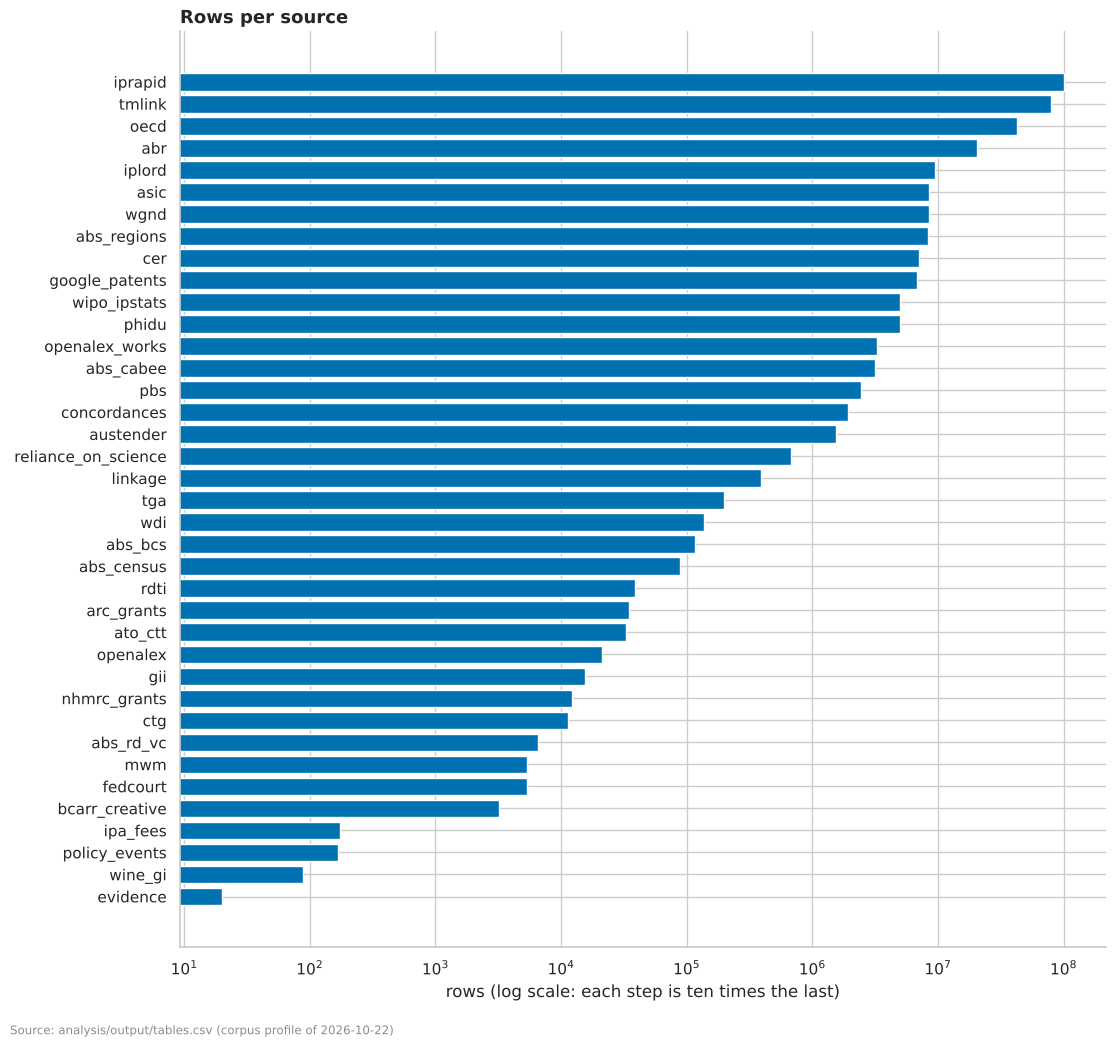

In [3]:
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(by_source.index, by_source.rows, color=style.MAIN)
ax.set_xscale("log")
ax.set_xlabel("rows (log scale: each step is ten times the last)")
ax.set_title("Rows per source")
style.source(fig, "analysis/output/tables.csv (corpus profile of 2026-10-22)")

#### Observation U0 (descriptive; a worked example of the format)

- **Size.** The corpus holds 152 tables from 38 sources: 314,742,745 rows in all.
- **Concentration.** Three sources hold 70.4% of the rows: IP RAPID (31.88%), TM-Link (25.1%) and the OECD panels
  (13.43%).
- **What this means for the EDA.** Row counts measure how much a source records, not how much it matters to the
  research questions. This notebook is therefore ordered by unit of analysis (rights, firms, places, countries), not
  by size, and the largest sources enter through the lenses built from them.

## 1. Lens: IP rights (one row per right)

Every patent, trade mark, design and plant breeder's right in IP Australia's IP RAPID data, from 1904 to October 2026.
Built from `iprapid/*_rights`.

### 1.0 Data overview and sanity checks

In [4]:
rights = load_lens("rights")
print(f"{len(rights):,} rows, {rights.shape[1]} columns")
uni.overview(rights, "rights")

4,368,006 rows, 28 columns


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
application_number,Application number,id,str,100,4368006,NaN,NaN,NaN
ip_right_type,Type of right,category,str,100,4,NaN,NaN,trade_mark (53.5%)
ip_right_sub_type,Sub-type of right,category,str,100,12,NaN,NaN,trade_mark (53.3%)
patent_type,Type of patent,category,str,40.12,3,NaN,NaN,standard (82.2%)
status,Current status,category,str,100,27,NaN,NaN,ceased (28.1%)
application_date,Application date,date,datetime64[s],98.58,37923,1904-02-13,2026-10-17,2013-04-12 (0.0%)
filing_fy,Financial year of application,year,Int64,98.58,124,1904,2027,2026 (3.5%)
priority_date,Priority date,date,datetime64[s],98.59,39352,1904-02-13,2026-10-16,2013-03-15 (0.1%)
registered_date,Date registered or granted,date,datetime64[s],57.74,24430,1901-01-01,2026-10-16,2016-01-15 (0.1%)


Rows that repeat a right (same type and application number): 0


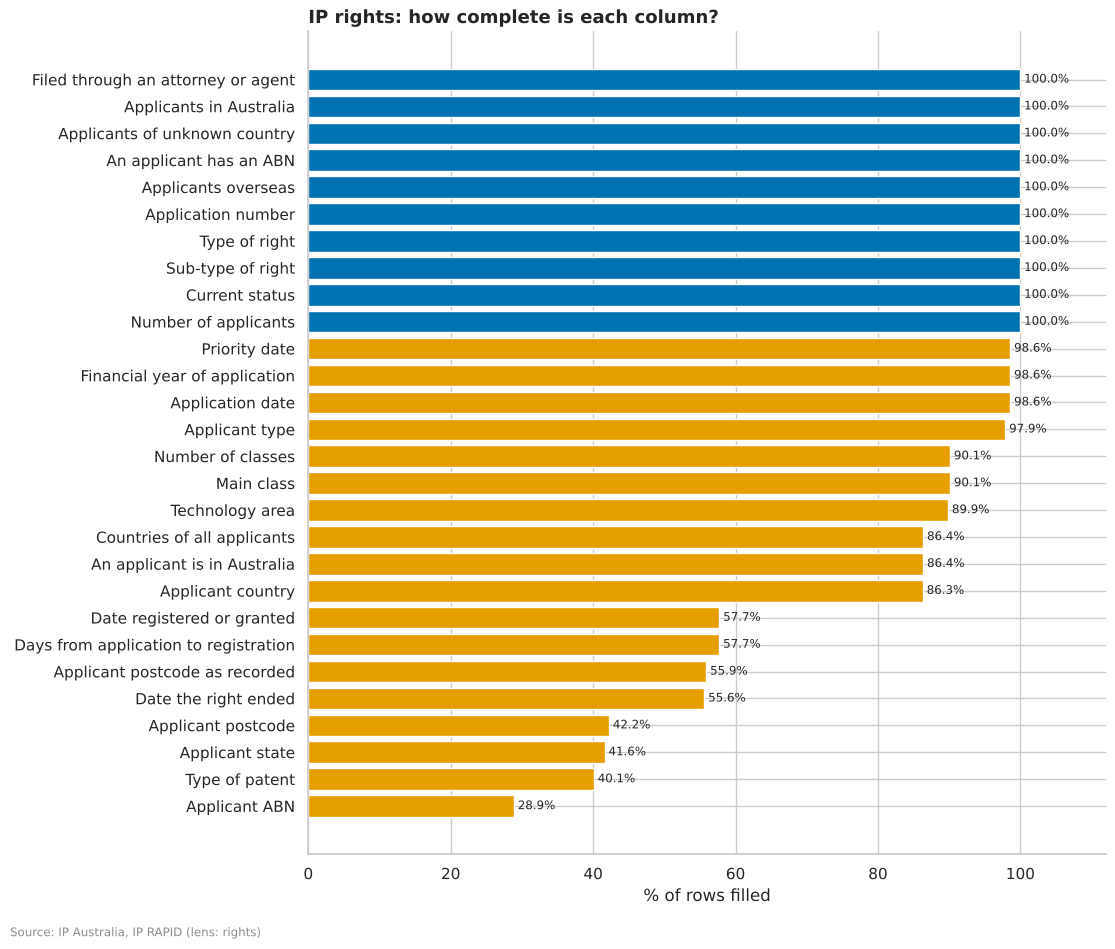

In [5]:
dupes = sql("SELECT count(*) - count(DISTINCT (ip_right_type, application_number)) AS n FROM {lens/rights}")
print(f"Rows that repeat a right (same type and application number): {dupes.n[0]:,}")
fig = uni.missing(rights, "rights", title="IP rights: how complete is each column?")
style.source(fig, "IP Australia, IP RAPID (lens: rights)")

#### Observations from the overview
_To be written._ Leads to check, found while building the skeleton:
- 264,024 patent rows are *provisional* applications (placeholders that are never granted). They are now separated
  from standard and second-tier patents (`patent_type`, ADR 0009).
- Applicant origin has three values (ADR 0009): 517,145 patents, 40,726 designs and 37,656 trade marks have no
  applicant country and are "origin unknown", not overseas. Most are patents filed before 1980.
- 50,711 patents and 11,143 designs have no application date; almost all are also of unknown origin.
- `days_to_registration` runs from -28,757 to 35,127 days (about -79 to +96 years), and the earliest
  `registered_date` is 1901-01-01, before the earliest application (1904-02-13): likely placeholder dates.
  1,497 rights (1,493 of them trade marks) are registered before they were applied for.
- `main_class` and `main_area` hold different class systems for different rights (see `variables.yaml`), so they are
  described per type of right.

### 1.1 Type and sub-type of right

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q2. **Helpers:** `uni.counts`.

- [ ] Counts and shares by type and sub-type (`uni.counts`).
- [ ] Shares by `patent_type`. Settled (ADR 0009): standard, provisional and second-tier patents are counted apart,
  and headline figures use standard patents.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.2 Applications over time (`filing_fy`)

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q4. **Helpers:** `sql`, `uni.over_time`.

- [ ] Applications per financial year, by type, from Australian, overseas and origin-unknown applicants
  (`uni.over_time`).
- [ ] Check that recent years are complete (FY2025 and FY2026 against earlier years).
- [ ] Mark known breaks: the end of innovation patents (2021), fee changes (`policy_events`).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.3 Status and how rights end

*Planned for Stage 1 (not yet run).* **Informs:** Q1. **Helpers:** `uni.counts`.

- [ ] Status by type; what 'unknown' means for old rights.
- [ ] Share of rights that lapse, expire, are withdrawn or refused.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.4 Time to registration (`days_to_registration`)

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q4. **Helpers:** `uni.describe`, `uni.distribution`, `uni.bin_check`.

- [ ] Distribution by type (`uni.distribution`, log scale where skewed), with a bin-width check (`uni.bin_check`).
- [ ] The 1,497 negative values: data errors, or a rule (for example, backdated registration)?

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.5 Who applies: country, type, ABN, agent

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`.

- [ ] Share of applications from Australian applicants, by type.
- [ ] Organisations against individuals; share with an ABN; share filed through an attorney.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.6 What is protected: classes and technology areas

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q3. **Helpers:** `uni.counts`, `uni.describe`.

- [ ] Top IPC subclasses and WIPO technology areas (patents); Nice classes (trade marks); Locarno classes (designs).
- [ ] Number of classes and applicants per right (`uni.describe`).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.7 Where Australian applicants are

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`.

- [ ] Applicant state, and how many Australian applicants have a usable postcode.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 1.8 Summary of the IP rights lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 2. Lens: Firms (one row per ABN)

Every ABN that appears in IP Australia's data, the R&D Tax Incentive, AusTender or the ATO's tax transparency
reports (the corpus's `linkage/abn_spine`), with their IP applications, R&D claims, income and place.

### 2.0 Data overview and sanity checks

In [6]:
firms = load_lens("firms")
print(f"{len(firms):,} rows, {firms.shape[1]} columns; {firms.abn.nunique():,} distinct ABNs")
uni.overview(firms, "firms")

391,983 rows, 34 columns; 391,983 distinct ABNs


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
abn,ABN,id,str,100,391983,NaN,NaN,NaN
entity_type,Entity type (ABR),category,str,99.98,57,NaN,NaN,Australian Private Company (74.5%)
entity_group,Entity group,category,str,99.98,8,NaN,NaN,Private company (74.5%)
abn_active,ABN is active,binary,boolean,99.98,2,NaN,NaN,True (62.2%)
gst_registered,Registered for GST,binary,boolean,99.98,2,NaN,NaN,False (51.5%)
state,State,category,str,99.98,9,NaN,NaN,NSW (35.5%)
postcode,Postcode,category,str,99.3,2798,NaN,NaN,2000 (4.6%)
remoteness,Remoteness of postcode,category,str,98.91,6,NaN,NaN,Major Cities of Australia (85.2%)
irsad_decile,Advantage of postcode (IRSAD decile),numeric,float64,98.55,10,1,10,10.0 (34.0%)


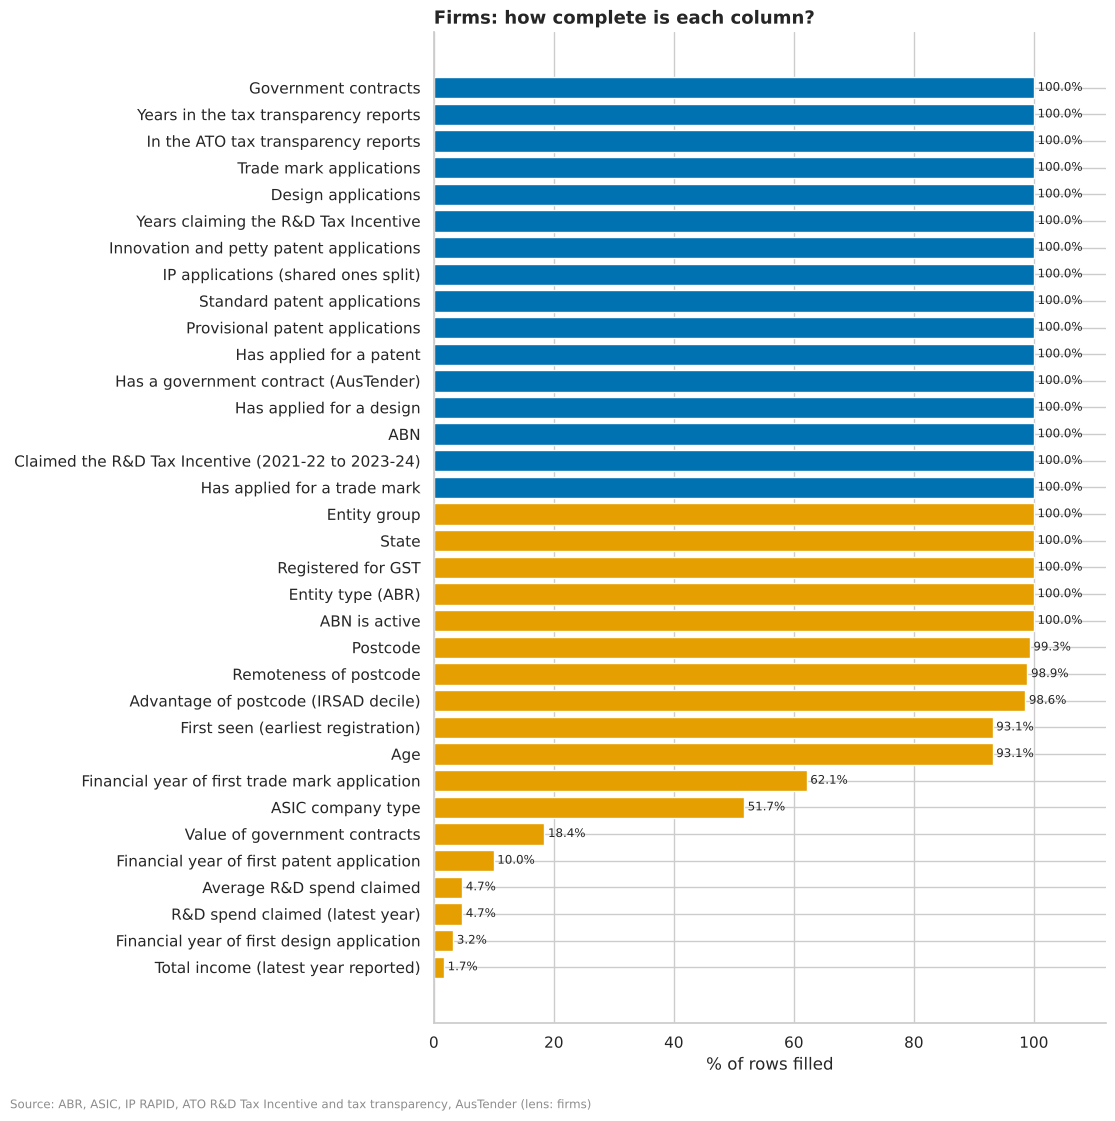

In [7]:
fig = uni.missing(firms, "firms", title="Firms: how complete is each column?")
style.source(fig, "ABR, ASIC, IP RAPID, ATO R&D Tax Incentive and tax transparency, AusTender (lens: firms)")

#### Observations from the overview
_To be written._ To check here: who is in the lens (it is not all Australian businesses, only those in at least one
source), so rates computed on it are rates among these ABNs.

### 2.1 Entity type and status

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`.

- [ ] Entity groups, active ABNs, GST registration (`uni.counts`).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.2 Age

*Planned for Stage 1 (not yet run).* **Informs:** Q2, Q3. **Helpers:** `uni.distribution`, `uni.bin_check`.

- [ ] Distribution of age in years; spikes at known registration waves (the ABN began in 1999-2000).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.3 IP use

*Planned for Stage 1 (not yet run).* **Informs:** Q2, Q3. **Helpers:** `uni.describe`, `uni.distribution(log=True)`.

- [ ] How many firms hold each kind of right; the distribution of applications per firm (expected to be very skewed).
- [ ] The heaviest filers: how much of all filing do the top 1% of firms account for?

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.4 R&D, income and government contracts

*Planned for Stage 1 (not yet run).* **Informs:** Q3, Q4. **Helpers:** `uni.describe`, `uni.distribution(log=True)`.

- [ ] R&D Tax Incentive claims (years, spend); income for the large firms in the tax reports; AusTender contracts.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.5 Place: state, remoteness, advantage

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`.

- [ ] Firms by state, remoteness and IRSAD decile of their postcode.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 2.6 Summary of the firms lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 3. Lens: Places (one row per postal area)

Every Australian postal area, with its population, remoteness, socio-economic indexes (SEIFA 2021), Census medians,
business counts (ABR) and IP applications by Australian applicants over FY2017 to FY2026.

### 3.0 Data overview and sanity checks

In [8]:
regions = load_lens("regions")
print(f"{len(regions):,} postal areas, {regions.shape[1]} columns; {regions.persons.sum():,.0f} people")
uni.overview(regions, "regions")

2,641 postal areas, 31 columns; 25,365,506 people


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
poa_code,Postal area,id,str,100,2641,NaN,NaN,NaN
state,State,category,str,100,9,NaN,NaN,Victoria (26.3%)
remoteness,Remoteness,category,str,100,5,NaN,NaN,Major Cities of Australia (37.7%)
share_major_cities,Share of people in major cities,rate,float64,99.92,138,0,1,0.0 (61.6%)
persons,Population (2021 Census) (people),count,Int64,100,2280,0,"129,883",115 (0.2%)
irsad_score,Socio-economic advantage and disadvantage (IRS...,numeric,float64,99.36,378,659,"1,185",939.0 (1.0%)
irsad_decile,IRSAD decile,numeric,float64,99.36,10,1,10,9.0 (10.0%)
irsd_score,Socio-economic disadvantage (IRSD score),numeric,float64,99.36,349,492,"1,166",1006.0 (1.1%)
irsd_decile,IRSD decile,numeric,float64,99.36,10,1,10,9.0 (10.0%)


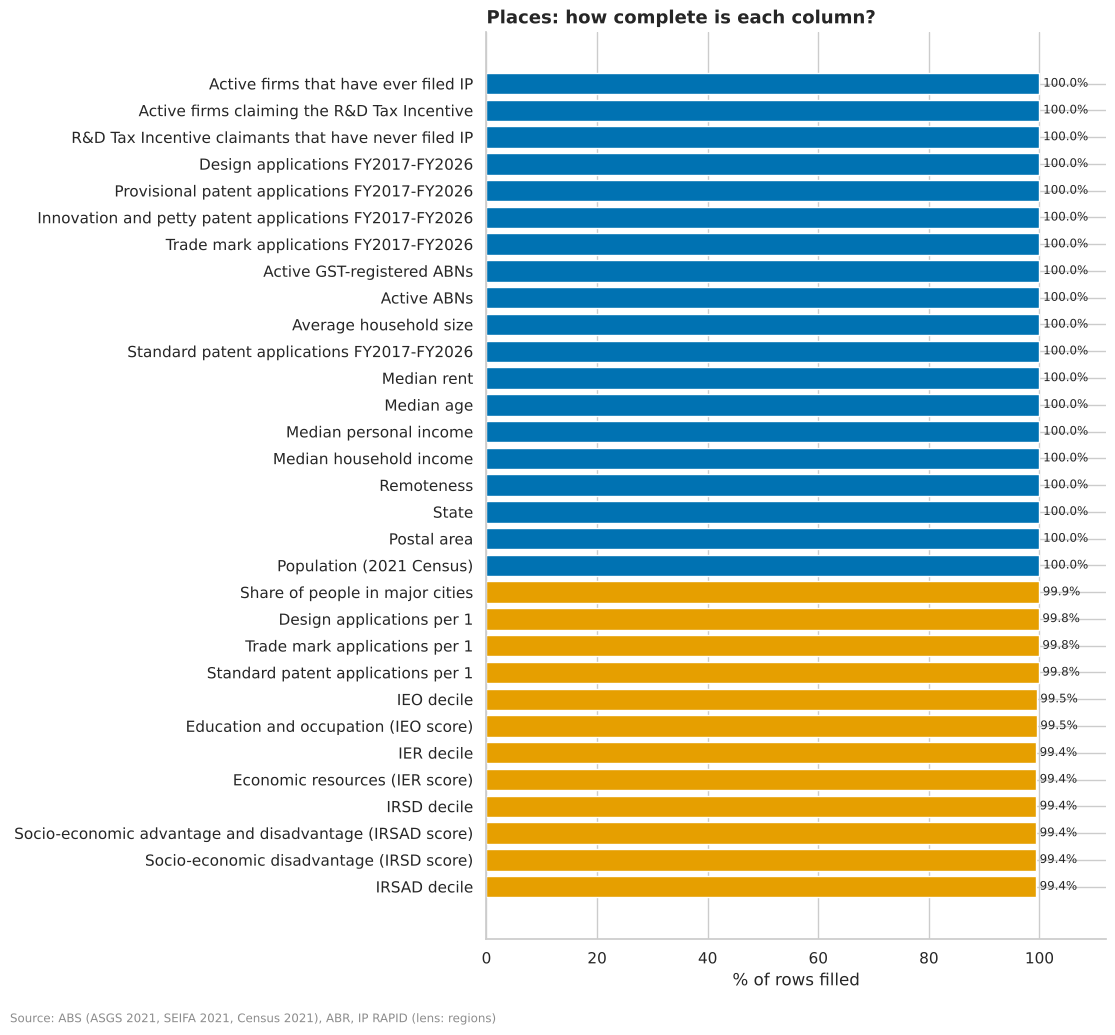

In [9]:
fig = uni.missing(regions, "regions", title="Places: how complete is each column?")
style.source(fig, "ABS (ASGS 2021, SEIFA 2021, Census 2021), ABR, IP RAPID (lens: regions)")

#### Observations from the overview
_To be written._ Leads to check, found while building the skeleton:
- Population, median age and median incomes reach 0: postal areas with no usual residents (for example, business
  districts or parks). Rates per person or per business will be unstable or undefined there.
- SEIFA scores are missing for 0.64% of postal areas (99.36% filled).

### 3.1 Population and businesses

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.distribution(log=True)`.

- [ ] Distribution of people and GST-registered businesses per postal area; very small areas.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.2 Remoteness and socio-economic indexes

*Planned for Stage 1 (not yet run).* **Informs:** Q2. **Helpers:** `uni.counts`, `uni.distribution`.

- [ ] Postal areas by remoteness; the four SEIFA scores and deciles.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.3 IP applications and rates

*Planned for Stage 1 (not yet run).* **Informs:** Q2, Q4. **Helpers:** `uni.describe`, `uni.distribution(log=True)`.

- [ ] Applications per postal area and per 1,000 businesses, by type: how concentrated (share of the top 10 areas).
- [ ] Areas with no applications at all.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.4 R&D claimants and 'missing filers'

*Planned for Stage 1 (not yet run).* **Informs:** Q4. **Helpers:** `uni.describe`.

- [ ] R&D Tax Incentive claimants per area, and those that have never filed IP.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 3.5 Summary of the places lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 4. Lens: Australia and other countries (one row per country, year and indicator)

22 World Bank indicators (IP filings, IP royalties, R&D, researchers, GDP, exports) and WIPO's filings by residents
of each country at every office, for every country. One variable here is one indicator.

### 4.0 Data overview and sanity checks

In [10]:
coverage = sql("""
    SELECT source, indicator, any_value(indicator_name) AS name,
           count(DISTINCT iso3) AS countries, min(year) AS first_year, max(year) AS last_year,
           count(*) FILTER (australia) AS australia_years,
           max(year) FILTER (australia) AS australia_latest
    FROM {lens/national} GROUP BY 1, 2 ORDER BY 1, 2
""")
coverage

,source,indicator,name,countries,first_year,last_year,australia_years,australia_latest
0,WDI,BM.GSR.ROYL.CD,"Charges for the use of intellectual property, ...",179,1960,2025,37,2025
1,WDI,BX.GSR.ROYL.CD,"Charges for the use of intellectual property, ...",174,1962,2025,37,2025
2,WDI,BX.KLT.DINV.WD.GD.ZS,"Foreign direct investment, net inflows (% of GDP)",203,1970,2025,56,2025
3,WDI,GB.XPD.RSDV.GD.ZS,Research and development expenditure (% of GDP),156,1996,2024,14,2021
4,WDI,IC.BUS.NDNS.ZS,"New business density (new registrations per 1,...",183,2006,2024,19,2024
5,WDI,IC.BUS.NREG,New businesses registered (number),183,2006,2024,19,2024
6,WDI,IP.IDS.NRCT,"Industrial design applications, nonresident, b...",145,1980,2024,21,2024
7,WDI,IP.IDS.RSCT,"Industrial design applications, resident, by c...",146,1980,2024,21,2024
8,WDI,IP.JRN.ARTC.SC,Scientific and technical journal articles,197,1996,2023,28,2023
9,WDI,IP.PAT.NRES,"Patent applications, nonresidents",170,1980,2024,45,2024


#### Observations from the overview
_To be written._ Leads to check, found while building the skeleton:
- Australia's series for researchers in R&D ends in 2010 and for technicians in 2008; R&D expenditure (% of GDP) ends
  in 2021. The OECD's MSTI tables in the corpus may fill these gaps.
- The WIPO series count applications by residents of each country at every office, so they include Australians'
  filings abroad; the WDI patent series count filings at the national office only.

### 4.1 Each indicator for Australia over time

*Planned for Stage 1 (not yet run).* **Informs:** Q1. **Helpers:** `sql`, `uni.over_time`.

- [ ] Australia's series against the OECD median and range, one small chart per indicator.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 4.2 Each indicator across countries (latest year)

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q4. **Helpers:** `uni.distribution`.

- [ ] Distribution across OECD countries in the latest common year, with Australia marked.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 4.3 Summary of the national lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 5. Lens: Australia over time (one row per month)

IP Australia's whole register, month by month, from January 1904 to September 2026: applications by type and by
Australian or overseas applicant; what happened to rights (grants, lapses, expiries, oppositions, ownership
transfers, extensions of term); and the month each of 13 IP policy changes took effect. A series is blank, not 0,
before its records begin.

### 5.0 Data overview and sanity checks

In [11]:
timeline = load_lens("timeline")
span = f"{timeline.month.min():%B %Y} to {timeline.month.max():%B %Y}"
print(f"{len(timeline):,} months, {span}; {timeline.shape[1]} columns")
uni.overview(timeline, "timeline")

1,473 months, January 1904 to September 2026; 34 columns


,label,kind,dtype,% filled,distinct,min,max,most common
column,,,,,,,,
month,Month,date,datetime64[s],100,1473,1904-01-01,2026-09-01,NaN
year,Year,year,Int64,100,123,1904,2026,1904 (0.8%)
month_of_year,Month of the year,category,int64,100,12,1,12,1 (8.4%)
fy,Financial year,year,Int64,100,124,1904,2027,1905 (0.8%)
days_in_month,Days in the month,count,Int64,100,4,28,31,31 (58.3%)
patents_standard_au,Standard patent applications from Australian a...,count,Int64,99.66,221,0,"1,018",0 (54.0%)
patents_standard_overseas,Standard patent applications from overseas app...,count,Int64,99.66,524,0,"5,407",0 (49.3%)
patents_standard_origin_unknown,Standard patent applications of unknown origin,count,Int64,99.93,587,0,"1,334",0 (18.8%)
patents_provisional,Provisional patent applications,count,Int64,44.4,358,0,"1,274",0 (4.4%)


In [12]:
# When each monthly series begins, its total, and its busiest month
series = [c for c in timeline.columns if style.kind("timeline", c) == "count" and c != "days_in_month"]
pd.DataFrame(
    {
        "first month": {c: f"{timeline.month[timeline[c].notna()].min():%Y-%m}" for c in series},
        "total": timeline[series].sum(),
        "busiest month": {c: f"{timeline.month[timeline[c].fillna(0).idxmax()]:%Y-%m}" for c in series},
        "count in busiest month": timeline[series].max(),
    }
)

,first month,total,busiest month,count in busiest month
patents_standard_au,1904-06,93720,2013-04,1018
patents_standard_overseas,1904-06,849114,2013-04,5407
patents_standard_origin_unknown,1904-02,445357,1969-07,1334
patents_provisional,1972-04,263554,2026-03,1274
patents_second_tier,1979-07,48241,2021-08,2789
trade_marks_au,1906-07,1395842,2020-09,5771
trade_marks_overseas,1906-07,896778,2025-07,3947
trade_marks_origin_unknown,1906-07,37655,1984-09,404
designs_au,1972-08,102302,2006-08,324
designs_overseas,1972-12,125736,2024-10,697


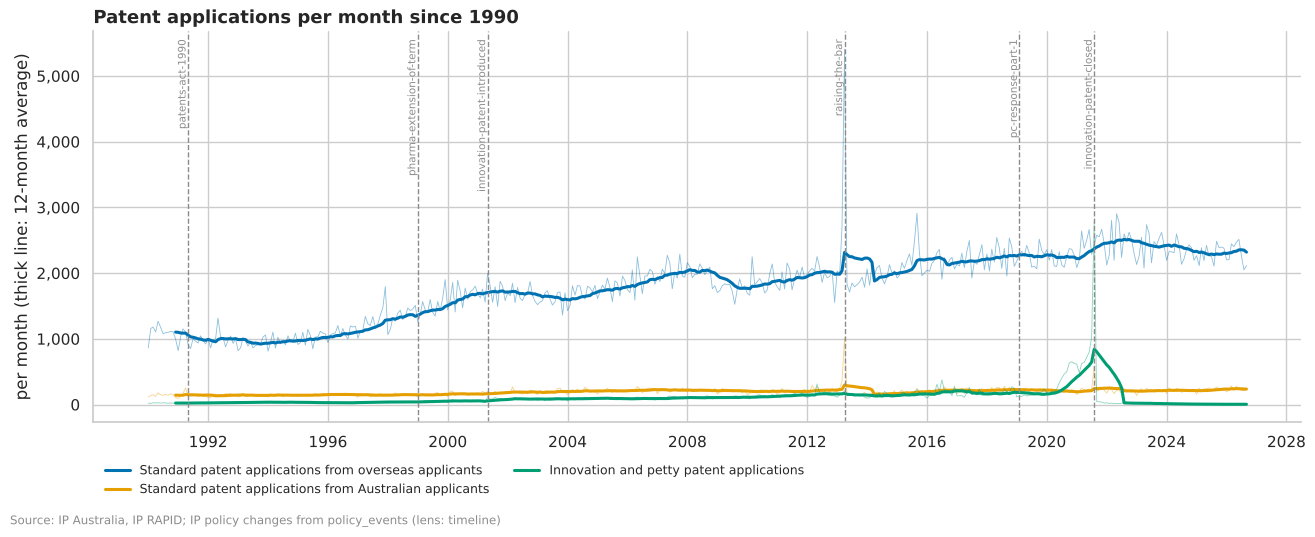

In [13]:
fig = uni.monthly(
    timeline,
    ["patents_standard_overseas", "patents_standard_au", "patents_second_tier"],
    start="1990-01-01",
    title="Patent applications per month since 1990",
    events=[  # the patent changes only
        "patents-act-1990",
        "pharma-extension-of-term",
        "innovation-patent-introduced",
        "raising-the-bar",
        "pc-response-part-1",
        "innovation-patent-closed",
    ],
)
style.source(fig, "IP Australia, IP RAPID; IP policy changes from policy_events (lens: timeline)")

#### Observations from the overview
_To be written._ Leads to check, found while building the lens:
- Rushes before rule changes: the busiest month for standard patent applications, from both Australian and overseas
  applicants, is April 2013, when the Raising the Bar reforms took effect; second-tier patent applications peak in
  August 2021, the month innovation patents closed (see the table above). These are the first candidates for the
  before-and-after comparisons in Stage 2.
- Designs registered begin in January 1970, which looks like a placeholder date rather than a real month.
- Left out of the lens, on purpose: renewals (their records stop in 2016 for designs and 2018 for trade marks), events
  IP RAPID marks as historical (dated on the day records moved between systems: 670,560 trade mark registrations are
  dated 10 November 2018), and fees over time (the corpus holds only today's fee schedule).
- Monthly counts depend on the length of the month (28 to 31 days, `days_in_month`) and its working days; the
  12-month average in the chart removes both.

### 5.1 Long-run trends in applications, by type and origin

*Planned for Stage 1 (not yet run).* **Informs:** Q1, Q2. **Helpers:** `uni.monthly`, `uni.over_time`.

- [ ] Applications per month for each type of right, from Australian, overseas and origin-unknown applicants, from
  1904 (`uni.monthly`).
- [ ] Australian applicants' share of rights with a known origin over time, from the decade the unknown share falls
  below 5% (the 1990s for standard patents).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 5.2 Seasonal patterns

*Planned for Stage 1 (not yet run).* **Informs:** Q4. **Helpers:** `uni.monthly`, `pandas` groupby on `month_of_year`.

- [ ] Average month-of-year profile of each series, relative to its 12-month average: holiday dips, end-of-year or end-of-financial-year rushes.
- [ ] Whether the pattern has changed over the decades.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 5.3 What happens to rights, over time

*Planned for Stage 1 (not yet run).* **Informs:** Q1. **Helpers:** `uni.monthly`.

- [ ] Grants and registrations, lapses, expiries, oppositions, ownership transfers and extensions of term per month.
- [ ] What IP RAPID's 'ceased' means, and how it differs from 'lapsed' (`iprapid/events` event types).

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 5.4 The 13 policy changes, one at a time

*Planned for Stage 1 (not yet run).* **Informs:** Q4, Q5. **Helpers:** `uni.monthly(events=[...])`.

- [ ] For each change, the series it targets in the 24 months either side, marked on the chart (`style.mark_events`).
- [ ] Which changes show a visible rush or step, and which none: descriptive only; Stage 2 compares before and after.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 5.5 Artefacts

*Planned for Stage 1 (not yet run).* **Informs:** all. **Helpers:** `uni.monthly`, `sql` on `iprapid/events`.

- [ ] Spikes from system changes or placeholder dates (for example January 1970); decide which months to exclude.

#### Observations
_To be written from the outputs above, each quoting its numbers._

### 5.6 Summary of the timeline lens
| # | Observation | Evidence | Strength | Carried to |
|---|---|---|---|---|
| | _To be written_ | | | |

## 6. Sources outside the five lenses

These are profiled, not explored variable by variable, unless a research question needs them. The profile of each
table is one call away: `data.corpus_columns("source", "table")`. `docs/catalogue.md` describes them all.

| Group | Sources | Planned in Stage 1 |
|---|---|---|
| IP detail | `iprapid` events, party, classification; `tmlink`; `google_patents`; `iplord` | Event types and their counts (renewals, lapses, oppositions, assignments); citation counts |
| Knowledge | `openalex`, `openalex_works`, `reliance_on_science`, `arc_grants`, `nhmrc_grants` | Size and time span; grants per year |
| Business surveys | `abs_bcs`, `abs_cabee`, `abs_rd_vc` | Which measures exist for IP protection and barriers (national, by size and industry) |
| Sectors | `pbs`, `tga`, `cer`, `bcarr_creative`, `wine_gi` | Size and time span |
| Law and policy | `fedcourt`, `policy_events`, `ipa_fees` | The dated events available for natural experiments later |
| Wellbeing and context | `oecd`, `gii`, `mwm`, `ctg`, `phidu`, `abs_census` | Which outcome measures exist for Australia |
| Reference | `concordances`, `wgnd`, `evidence` | Coverage only |

In [14]:
data.corpus_columns("policy_events", "events")

,column,type,null_rate,approx_distinct,min,max,example
0,id,VARCHAR,0,13,NaN,NaN,pct-accession
1,date,DATE,0,13,1980-03-31,2022-03-10,1980-03-31
2,rights,VARCHAR,0,6,NaN,NaN,patent
3,lever,VARCHAR,0,6,NaN,NaN,international filing route
4,event,VARCHAR,0,13,NaN,NaN,Australia joins the Patent Cooperation T
5,source,VARCHAR,0,5,NaN,NaN,https://www.wipo.int/pct/en/pct_contract
6,verify,BOOLEAN,0,2,NaN,NaN,false


## 7. Summary of Stage 1

### What each variable looks like, and what was decided
| # | Lens | Observation | Evidence | Strength | Decision for Stages 2 and 3 |
|---|---|---|---|---|---|
| | | _To be written_ | | | |

### Carried into Stage 2
_To be written: the pairs worth testing, and why._